### Data Ingestion & Sanitization

ds (Datestamp / Datetime) \
y_b (Target Variable - Binary) \
unique_id : user id \
y_e (Target Variable - Unknown/Energy) -> not defined in the task description.

In [3]:
import pandas as pd
import numpy as np

def load_and_prep_data(train_path,test_path):
    print("Loading data...")
    df_train = pd.read_csv(train_path, sep=';')
    try:
        df_test = pd.read_csv(test_path)
        if "ds" not in df_test.columns:
            df_test = pd.read_csv(test_path, sep=';')
    except:
        print("Error loading test data. Please check the file format and path.")
        df_test = None
    
    
    # Convert 'ds' to datetime
    print("parsing dates...")
    df_train['ds'] = pd.to_datetime(df_train['ds'])
    if df_test is not None:
        df_test['ds'] = pd.to_datetime(df_test['ds'])
    
    # sort chronologically per user as this is time-series
    print("Sorting time-series data...")
    df_train = df_train.sort_values(by=['unique_id', 'ds']).reset_index(drop=True)
    if df_test is not None:
        df_test = df_test.sort_values(by=['unique_id', 'ds']).reset_index(drop=True)
    
    # in training data, isolate primary binary target (y_b) and drop y_e to avoid confusion
    target_col = "y_b"
    print("\n --- Data Shape ---")
    print(f"Training data: {df_train.shape}")
    if df_test is not None:
        print(f"Test data: {df_test.shape}")
    print(f"\n Global Charging Rate (target mean): {df_train[target_col].mean():.4f}")
    return df_train, df_test, target_col

train_df, test_df, target = load_and_prep_data('level_1_train.csv', 'level_1_test_submission.csv')

Loading data...
parsing dates...
Sorting time-series data...

 --- Data Shape ---
Training data: (164160, 4)
Test data: (21960, 3)

 Global Charging Rate (target mean): 0.0577


The target mean is the average of our y_b column. Since its a combination of charging(1) and rest(0), calculating the mean is same as calculating the percentage of 1's in the dataset. 
- 0.057 == 5.77%
- across all users and all hours in our train_dataset, an Ev is actively charging only 5.77% of time.
- rremaining 94.23% of the time, the chargers are sitting idle



### Feature Engineering (Extracting time and user habits)

In [5]:
def engineer_features(train_df, test_df):
    # make a copy so that it won't affect alteration 
    train = train_df.copy()
    test = test_df.copy() if test_df is not None else None
    
    def add_temporal_features(df):
        df['hour'] = df["ds"].dt.hour
        df['day_of_week'] = df['ds'].dt.dayofweek  # Monday=0, Sunday=6
        df['is_weekend'] = df['day_of_week'].isin([5,6]).astype(int)
        
        # lets add a binary flag for working hours (8am-5pm)
        df["is_business_hours"] = df['hour'].between(8, 17).astype(int)
        return df
    
    train = add_temporal_features(train)
    if test is not None:
        test = add_temporal_features(test)
        
    print("\n --- user hour profiles ---")
    # We calculate the historical probability that a specific user charges at a specific hour
    user_profiles = train.groupby(['unique_id', 'hour'])['y_b'].mean().reset_index()
    user_profiles.rename(columns={'y_b': 'user_hour_prob'}, inplace=True)
    
    train = train.merge(user_profiles, on=['unique_id', 'hour'], how='left')
    #print("Merged user hour profiles into training data.:", train.head())
    if test is not None:
        test = test.merge(user_profiles, on=['unique_id', 'hour'], how='left')
        test['user_hour_prob'] = test['user_hour_prob'].fillna(0.0577)
    print("Feature engineering completed.")
    
    features = ['hour', 'day_of_week', 'is_weekend', 'is_business_hours', 'user_hour_prob']
    print(f"\nFeatures created: {features}")
    return train, test, features
train_features, test_features, feature_cols = engineer_features(train_df, test_df)
print("\nFirst 3 rows with new features:")
print(train_features[['unique_id', 'ds', 'y_b'] + feature_cols].head(3))
    


 --- user hour profiles ---
Feature engineering completed.

Features created: ['hour', 'day_of_week', 'is_weekend', 'is_business_hours', 'user_hour_prob']

First 3 rows with new features:
                          unique_id                  ds  y_b  hour  \
0  1679091c5a880faf6fb5e6087eb1b2dc 2024-01-01 00:00:00  0.0     0   
1  1679091c5a880faf6fb5e6087eb1b2dc 2024-01-01 01:00:00  0.0     1   
2  1679091c5a880faf6fb5e6087eb1b2dc 2024-01-01 02:00:00  0.0     2   

   day_of_week  is_weekend  is_business_hours  user_hour_prob  
0            0           0                  0             0.0  
1            0           0                  0             0.0  
2            0           0                  0             0.0  


#### Did the features we just created actually separate the signal (charging) from the noise (idle)?

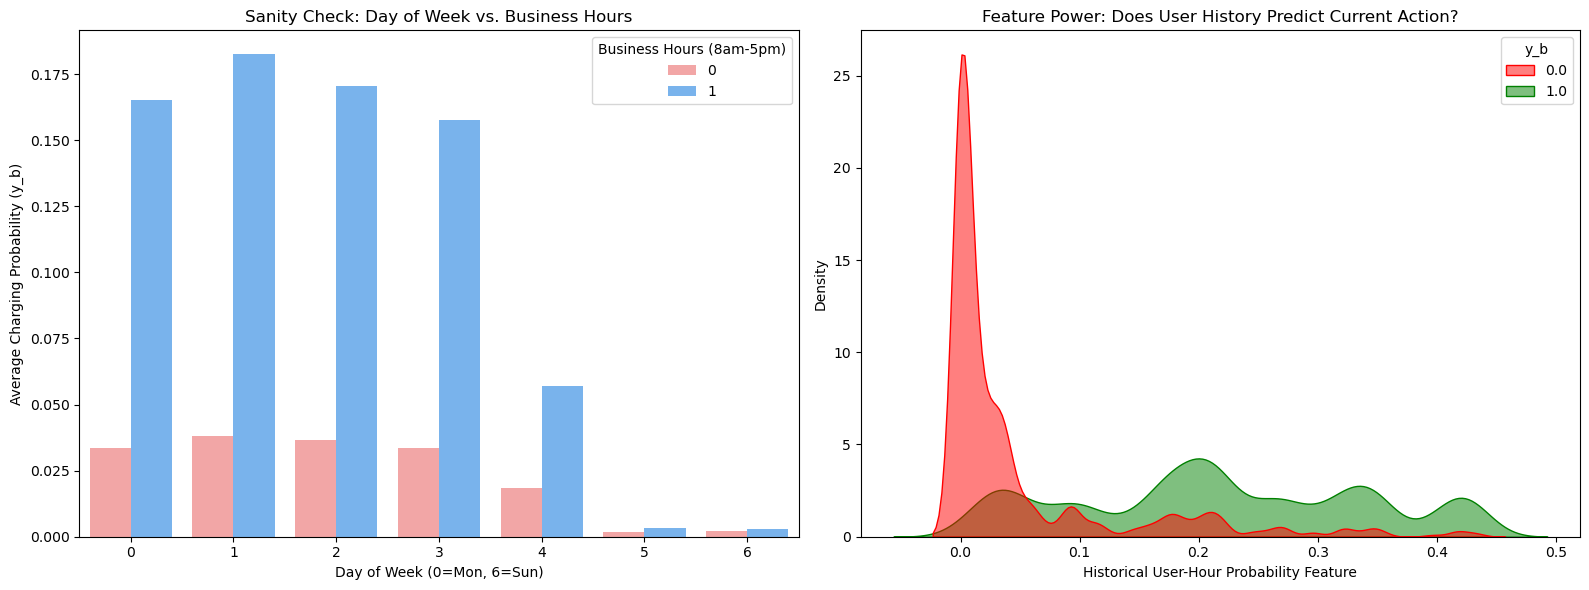

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_engineered_features(train_features):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # plot 1: Day of Week vs. Business Hours 
    sns.barplot(
        data=train_features, 
        x='day_of_week', 
        y='y_b', 
        hue='is_business_hours',
        palette=['#ff9999', '#66b3ff'], 
        ax=axes[0],
        errorbar=None 
    )
    axes[0].set_title('Sanity Check: Day of Week vs. Business Hours')
    axes[0].set_xlabel('Day of Week (0=Mon, 6=Sun)')
    axes[0].set_ylabel('Average Charging Probability (y_b)')
    axes[0].legend(title='Business Hours (8am-5pm)')

    # plot 2: 
    # We use a KDE plot to see if our user_hour_prob feature separates the 0s and 1s
    sns.kdeplot(
        data=train_features, 
        x='user_hour_prob', 
        hue='y_b', 
        fill=True, 
        common_norm=False, 
        palette={0.0: 'red', 1.0: 'green'},
        alpha=0.5,
        ax=axes[1]
    )
    axes[1].set_title('Feature Power: Does User History Predict Current Action?')
    axes[1].set_xlabel('Historical User-Hour Probability Feature')
    axes[1].set_ylabel('Density')

    plt.tight_layout()
    plt.show()

visualize_engineered_features(train_features)

Plot 1: \
Massive blue bars for Monday-Friday (Days 0-4), and almost non-existent red bars. \
On the weekend (Days 5-6), both bars should be tiny. This proves our is_business_hours \
and is_weekend features are capturing real-world variance.

Plot 2: \
Notice the massive red spike exactly at 0.0. When a charger is idle, \
the historical probability for that user at that time is almost always zero. \
Conversely, the green distribution (active charging) shifts entirely to the right.
- STRONG CLASS SEPARATION


### Validation Strategy (Crucial for time-series data)



### Model Training (Selecting an algorithm optimized for probability)



### Calibration & Submission (Ensuring our Brier score is as low as possible)